In [21]:
import torch
import glob
import pandas as pd
import os
from IPython.display import Audio, display
import librosa, librosa.display
import matplotlib.pyplot as plt
import numpy as np
import random
!test -d BigVGAN || git clone -q https://github.com/NVIDIA/BigVGAN
!sed -i 's/proxies: Optional\[Dict\],/proxies: Optional[Dict] = None,/; s/resume_download: bool,/resume_download: bool = False,/' BigVGAN/bigvgan.py
!grep -n "proxies\|resume_download" BigVGAN/bigvgan.py
import sys; sys.path.insert(0, "BigVGAN")
import torch, bigvgan
from tqdm.auto import tqdm 
from torch.utils.data import Dataset, DataLoader, Subset
import torch.nn.functional as F
import math
import torch.nn as nn
%matplotlib inline
device = "cuda"
vocoder = bigvgan.BigVGAN.from_pretrained("nvidia/bigvgan_v2_22khz_80band_256x", use_cuda_kernel = False)
vocoder.remove_weight_norm()
vocoder = vocoder.eval().to(device)
print(vocoder.h.sampling_rate)
DATA = "/kaggle/input/datasets/abrandonwang/clotho-mel-clap/"
mels = np.load(DATA + "mels.npy", mmap_mode = "r")
stats = np.load(DATA + "mel_stats.npy")
MIN, MAX = stats[0], stats[1]
meta = pd.read_csv(DATA + "meta.csv")

422:        proxies: Optional[Dict] = None,
423:        resume_download: bool = False,
444:                proxies=proxies,
445:                resume_download=resume_download,
476:                proxies=proxies,
477:                resume_download=resume_download,


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:189: UserWarning: The `resume_download` argument is deprecated and ignored in `hf_hub_download`. Downloads always resume whenever possible.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Loading weights from nvidia/bigvgan_v2_22khz_80band_256x
Removing weight norm...
22050


In [35]:
class MelDataset(Dataset):
    def __init__(self, split):
        self.rows = meta.index[meta["split"] == split].to_numpy()
        self.audio = np.load(DATA + "clap_audio.npy", mmap_mode = "r")
        self.mels = np.load(DATA + "mels.npy", mmap_mode = "r")

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        row = self.rows[i]
        mel = torch.tensor(self.mels[row].astype("float32"))
        clap = torch.tensor(self.audio[row].astype("float32"))
        clap = F.normalize(clap, dim = 0)
        return mel, clap

train_data = MelDataset("train")
loader = DataLoader(train_data, batch_size = 32, shuffle = True, num_workers = 2)

In [36]:
mel, clap = next(iter(loader))
m = mel[0]
m = ((m + 1) / 2) * (MAX - MIN) + MIN
m = m.to(device)

with torch.inference_mode():
    wav = vocoder(m)
wav = wav.squeeze().cpu().numpy()
Audio(wav, rate = 22050)

In [37]:
T = 1000
betas = torch.linspace(0.0001, 0.02, T).to(device)
alphas = 1 - betas
alphas.to(device)
alpha_bar =  torch.cumprod(alphas, dim = 0)

def add_noise(x0, t):
    noise = torch.randn_like(x0)
    a = alpha_bar[t]
    a = a.view(-1, 1, 1, 1)
    noisy = torch.sqrt(a) * x0 + torch.sqrt(1 - a) * noise
    return noisy, noise

def time_embedding(t, dim = 32):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device = t.device) / half)
    args = t[:, None].float() * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim = 1)

class Block(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim = 32):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size = 3, padding = 1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size = 3, padding = 1)
        self.act = nn.SiLU()
        self.t_proj = nn.Linear(t_dim, out_ch)
    def forward(self, x, t_emb):
        h = self.conv1(x)
        h = self.act(h)
        tt = self.t_proj(t_emb)
        tt = tt[:, :, None, None]
        h = h + tt
        h = self.conv2(h)
        h = self.act(h)
        return h

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.cond_proj = nn.Linear(512, 32)
        self.block1 = Block(1, 32)
        self.down1 = nn.Conv2d(32, 32, kernel_size = 3, stride = 2, padding = 1)
        self.block2 = Block(32, 64)
        self.down2 = nn.Conv2d(64, 64, kernel_size = 3, stride = 2, padding = 1)
        self.mid = Block(64, 128)
        self.up = nn.Upsample(scale_factor = 2)
        self.block3 = Block(192, 64)
        self.block4 = Block(96, 32)
        self.out = nn.Conv2d(32, 1, kernel_size = 1)
    def forward(self, x, t, c):
        t_emb = time_embedding(t) + self.cond_proj(c)
        d1 = self.block1(x, t_emb)
        h = self.down1(d1)
        d2 = self.block2(h, t_emb)
        h = self.down2(d2)
        h = self.mid(h, t_emb)
        h = self.up(h)
        h = torch.cat([h, d2], dim = 1)
        h = self.block3(h, t_emb)
        h = self.up(h)
        h = torch.cat([h, d1], dim = 1)
        h = self.block4(h, t_emb)
        return self.out(h)

In [38]:
model = UNet().to(device)
x = mel.to(device)
c = clap.to(device)
t = torch.randint(0, T, (16,), device = device)
print(model(x, t, c).shape)
print(sum(p.numel() for p in model.parameters()))

RuntimeError: The size of tensor a (16) must match the size of tensor b (32) at non-singleton dimension 0

In [ ]:
model = UNet().to(device)
opt = torch.optim.Adam(model.parameters(), lr = 1e-3)
EPOCHS = 1
tiny = Subset(train_data, range(16))
tiny_loader = DataLoader(tiny, batch_size = 16, shuffle = True)
for epoch in range(EPOCHS):
    total = 0
    for mel, clap in tqdm(loader):
        mel = mel.to(device)
        c = clap.to(device)
        mask = torch.rand(c.shape[0], device = device) < 0.1
        c[mask] = 0
        t = torch.randint(0, T, (mel.shape[0],), device = device)
        noisy, noise = add_noise(mel, t)
        pred = model(noisy, t, c)
        loss = F.mse_loss(pred, noise)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total = total + loss.item()
    print(epoch, total / len(loader))
torch.save(model.state_dict(), "/kaggle/working/unet_mel.pt")
print(torch.cuda.max_memory_allocated() / 1e9, "GB")

In [31]:
real_mel, real_clap = next(iter(tiny_loader))
c = real_clap[:4].to(device)
c_none = torch.zeros_like(c)

with torch.no_grad():
    model.eval()
    x = torch.randn(4, 1, 80, 256, device = device)
    for t in range(999, -1, -1):
        t_batch = torch.full((4,), t, device = device)
        eps_none = model(x, t_batch, c_none)
        eps_label = model(x, t_batch, c)
        w = 1
        eps = eps_none + w * (eps_label - eps_none)
        mean = (1 / torch.sqrt(alphas[t])) * (x - (betas[t] / torch.sqrt(1 - alpha_bar[t])) * eps)
        if t > 0:
            x = mean + torch.sqrt(betas[t]) * torch.randn_like(x)
        else:
            x = mean

x = x.clamp(-1, 1)
m = ((x + 1) / 2) * (MAX - MIN) + MIN

with torch.inference_mode():
    wav = vocoder(m.squeeze(1))

for i in range(4):
    display(Audio(wav[i].squeeze().cpu().numpy(), rate = 22050))

In [32]:
m_real = ((real_mel[:4] + 1) / 2) * (MAX - MIN) + MIN

with torch.inference_mode():
    wav_real = vocoder(m_real.squeeze(1).to(device))

for i in range(4):
    display(Audio(wav_real[i].squeeze().cpu().numpy(), rate = 22050))

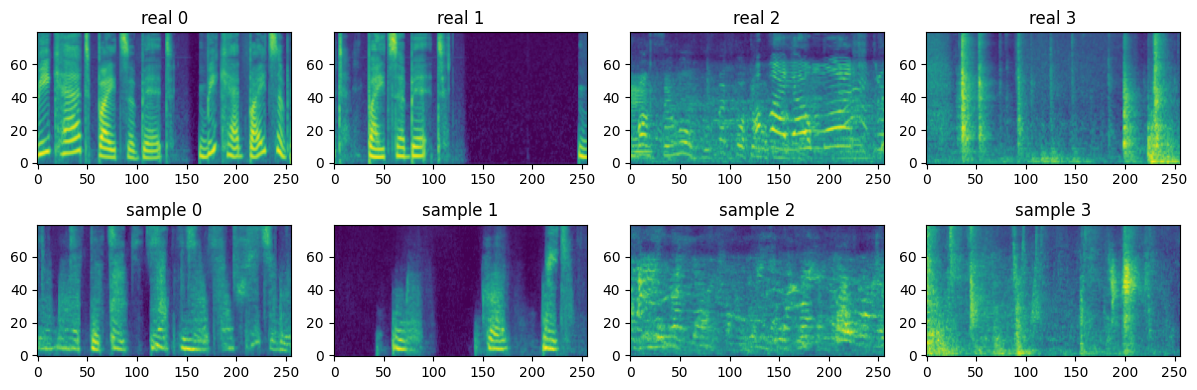

In [33]:
fig, axes = plt.subplots(2, 4, figsize = (12, 4))
for i in range(4):
    axes[0, i].imshow(real_mel[i].squeeze().numpy(), origin = "lower", aspect = "auto")
    axes[0, i].set_title(f"real {i}")
    axes[1, i].imshow(x[i].squeeze().cpu().numpy(), origin = "lower", aspect = "auto")
    axes[1, i].set_title(f"sample {i}")
plt.tight_layout()
plt.show()